In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS, Isomap
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 42
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.dpi'] = 100

## данные

In [2]:
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Genre': 'Gender', 'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Score'})
print(df.shape, '| пропусков:', df.isna().sum().sum())
df.describe().round(1)

(200, 5) | пропусков: 0


,CustomerID,Age,Income,Score
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


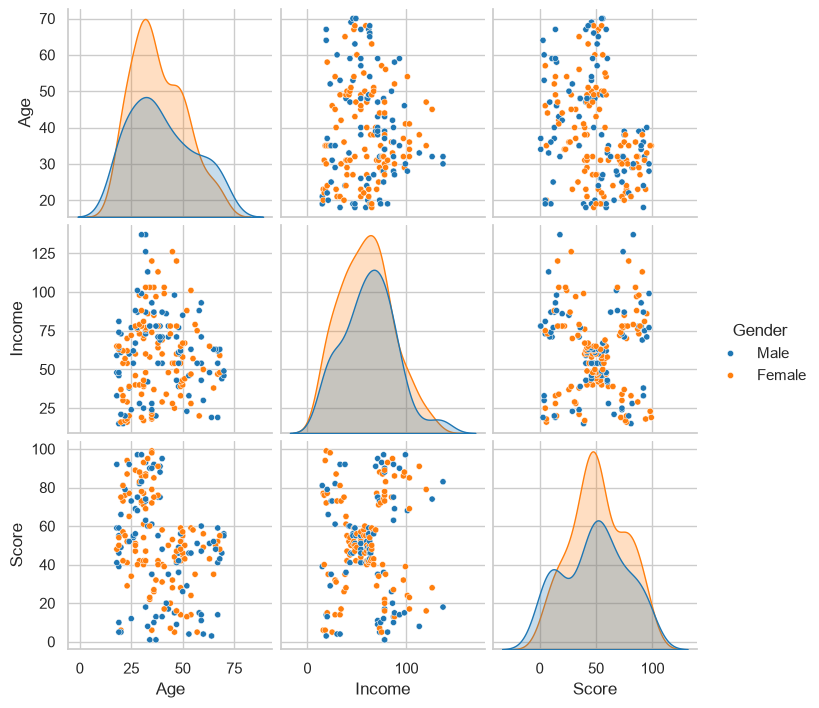

In [3]:
sns.pairplot(df.drop(columns='CustomerID'), hue='Gender', diag_kind='kde', height=2.4, plot_kws={'s': 20})
plt.show()

In [4]:
df.groupby('Gender')[['Age', 'Income', 'Score']].mean().round(1)

,Age,Income,Score
Gender,,,
Female,38.1,59.2,51.5
Male,39.8,62.2,48.5


In [5]:
FEATS = ['Age', 'Income', 'Score']
scaler = StandardScaler().fit(df[FEATS])
X = scaler.transform(df[FEATS])
X.shape

(200, 3)

### PCA

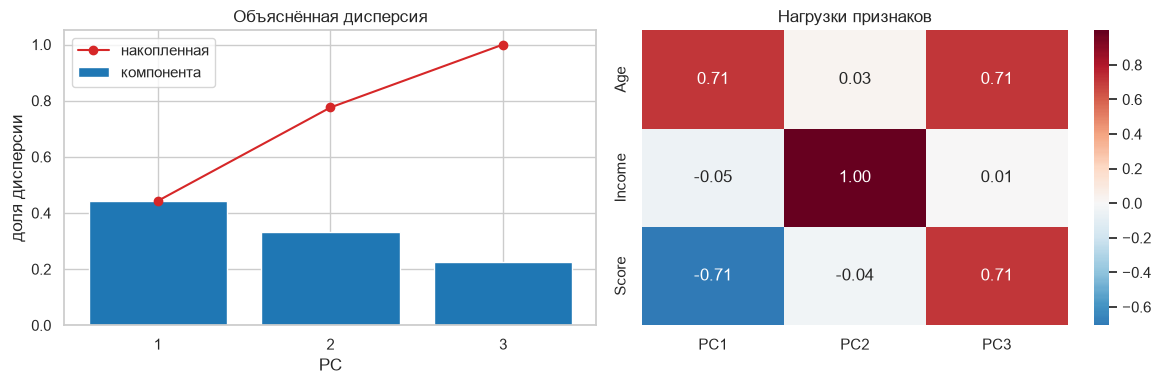

доля дисперсии: [0.443 0.333 0.224] | PC1+PC2 = 0.776


In [6]:
pca = PCA().fit(X)
evr = pca.explained_variance_ratio_

PCS = range(1, len(FEATS) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(PCS, evr, label='компонента')
ax[0].plot(PCS, evr.cumsum(), 'o-', c='C3', label='накопленная')
ax[0].set(xticks=list(PCS), xlabel='PC', ylabel='доля дисперсии', title='Объяснённая дисперсия')
ax[0].legend()

loadings = pd.DataFrame(pca.components_.T, index=FEATS, columns=[f'PC{i}' for i in PCS])
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[1])
ax[1].set_title('Нагрузки признаков')
plt.tight_layout(); plt.show()
print('доля дисперсии:', evr.round(3), '| PC1+PC2 =', evr[:2].sum().round(3))

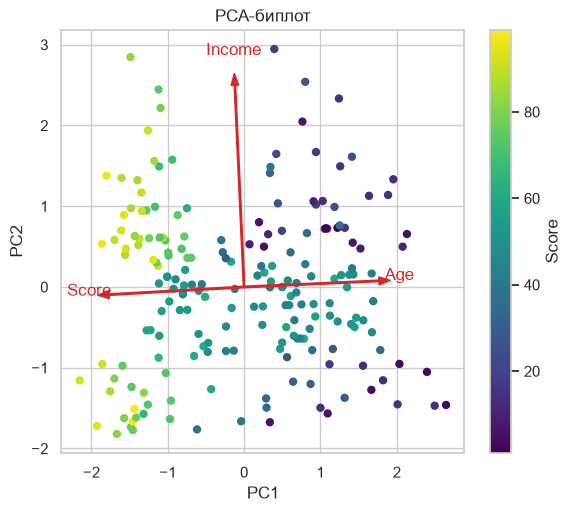

In [7]:
Z_pca = pca.transform(X)[:, :2]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(Z_pca[:, 0], Z_pca[:, 1], c=df['Score'], cmap='viridis', s=25)
for i, f in enumerate(FEATS):
    v = pca.components_[:2, i] * 2.5
    ax.arrow(0, 0, *v, color='C3', width=0.02, head_width=0.1)
    ax.text(*(v * 1.15), f, color='C3', fontsize=12, ha='center')
plt.colorbar(sc, label='Score')
ax.set(xlabel='PC1', ylabel='PC2', title='PCA-биплот')
plt.show()

### нелинейные методы

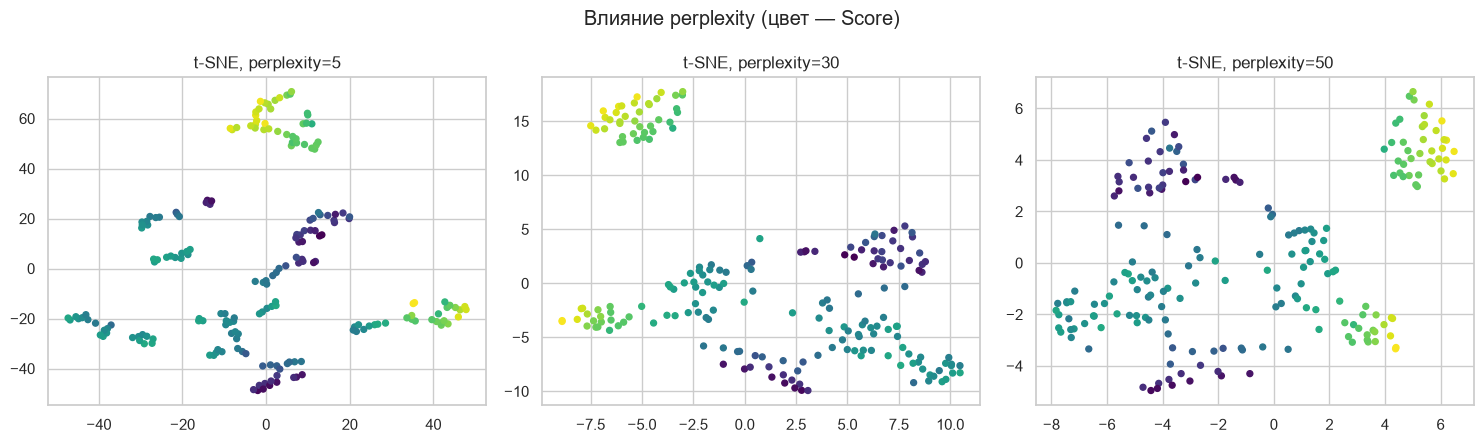

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, p in zip(ax, [5, 30, 50]):
    Z = TSNE(perplexity=p, random_state=SEED, init='pca').fit_transform(X)
    a.scatter(Z[:, 0], Z[:, 1], c=df['Score'], cmap='viridis', s=18)
    a.set_title(f't-SNE, perplexity={p}')
plt.suptitle('Влияние perplexity (цвет — Score)'); plt.tight_layout(); plt.show()

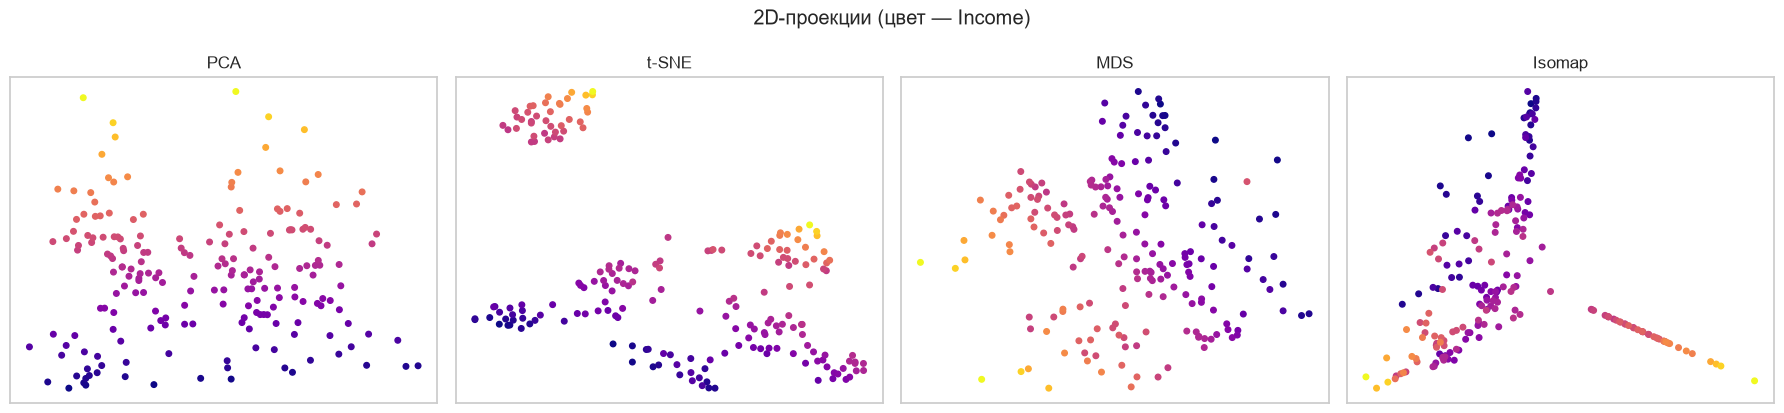

In [9]:
Z_tsne = TSNE(perplexity=30, random_state=SEED, init='pca').fit_transform(X)
Z_mds = MDS(n_components=2, random_state=SEED, n_init=4).fit_transform(X)
Z_iso = Isomap(n_neighbors=10, n_components=2).fit_transform(X)
EMB = {'PCA': Z_pca, 't-SNE': Z_tsne, 'MDS': Z_mds, 'Isomap': Z_iso}

fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
for a, (name, Z) in zip(ax, EMB.items()):
    a.scatter(Z[:, 0], Z[:, 1], c=df['Income'], cmap='plasma', s=16)
    a.set_title(name); a.set_xticks([]); a.set_yticks([])
plt.suptitle('2D-проекции (цвет — Income)'); plt.tight_layout(); plt.show()

## Подбор числа кластеров

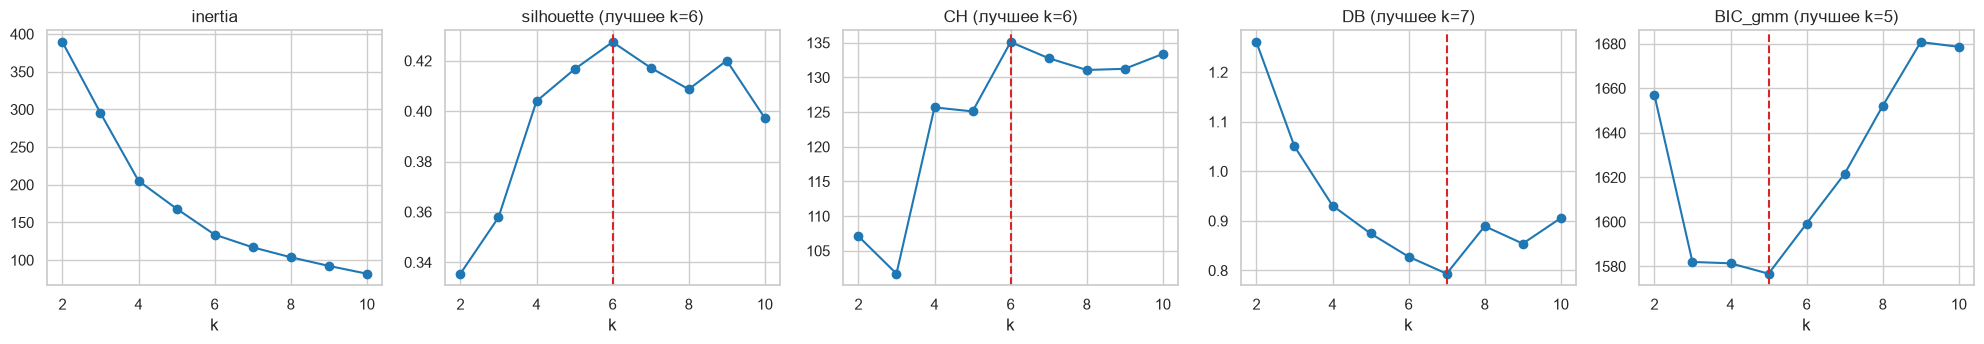

,inertia,silhouette,CH,DB,BIC_gmm
k,,,,,
2,389.386,0.335,107.096,1.261,1656.962
3,295.212,0.358,101.695,1.050,1581.976
4,205.225,0.404,125.676,0.931,1581.373
5,168.248,0.417,125.101,0.875,1576.708
6,133.868,0.427,135.102,0.828,1599.229
7,117.012,0.417,132.774,0.793,1621.623
8,103.829,0.409,131.074,0.889,1652.080
9,92.349,0.420,131.242,0.854,1680.783
10,81.987,0.397,133.385,0.906,1678.632


In [10]:
K = range(2, 11)
rows = []
for k in K:
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    gm = GaussianMixture(k, n_init=5, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X, km.labels_),
                 'CH': calinski_harabasz_score(X, km.labels_),
                 'DB': davies_bouldin_score(X, km.labels_),
                 'BIC_gmm': gm.bic(X)})
kdf = pd.DataFrame(rows).set_index('k')

fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
for a, col, best in zip(ax, kdf.columns, [None, 'max', 'max', 'min', 'min']):
    a.plot(kdf.index, kdf[col], 'o-')
    if best:
        kb = kdf[col].idxmax() if best == 'max' else kdf[col].idxmin()
        a.axvline(kb, ls='--', c='C3'); a.set_title(f'{col} (лучшее k={kb})')
    else:
        a.set_title(col)
    a.set_xlabel('k')
plt.tight_layout(); plt.show()
kdf.round(3)

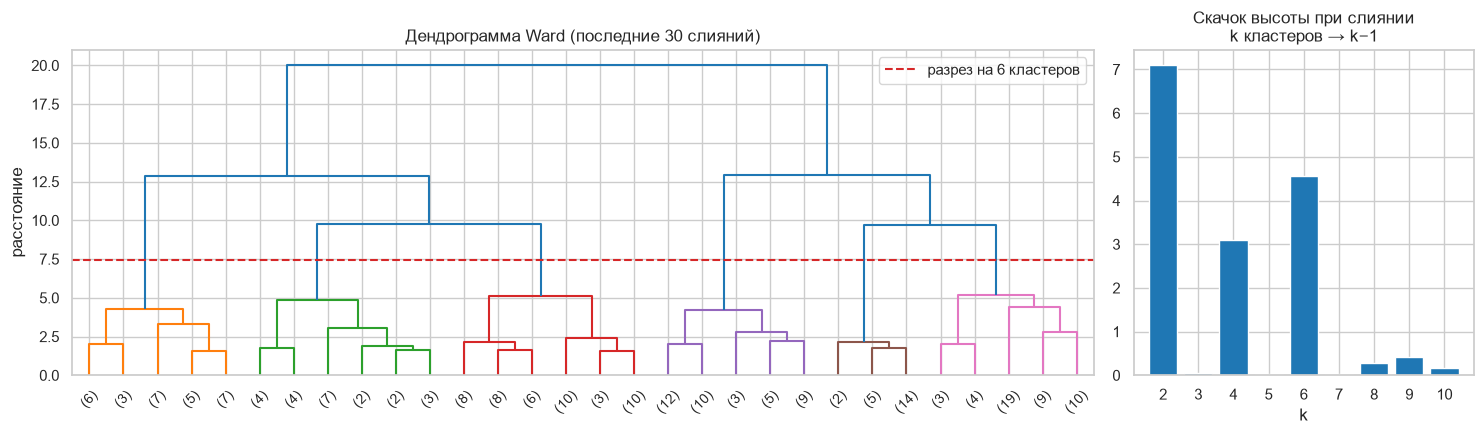

In [11]:
Lw = linkage(X, method='ward')
cut6 = (Lw[-6, 2] + Lw[-5, 2]) / 2  

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [3, 1]})
dendrogram(Lw, truncate_mode='lastp', p=30, ax=ax[0], color_threshold=cut6)
ax[0].axhline(cut6, c='C3', ls='--', label='разрез на 6 кластеров')
ax[0].set(title='Дендрограмма Ward (последние 30 слияний)', ylabel='расстояние'); ax[0].legend()

h = Lw[::-1, 2]                   
gain = h[:-1] - h[1:]               
ax[1].bar(range(2, 11), gain[:9])
ax[1].set(title='Скачок высоты при слиянии\nk кластеров → k−1', xlabel='k', xticks=range(2, 11))
plt.tight_layout(); plt.show()

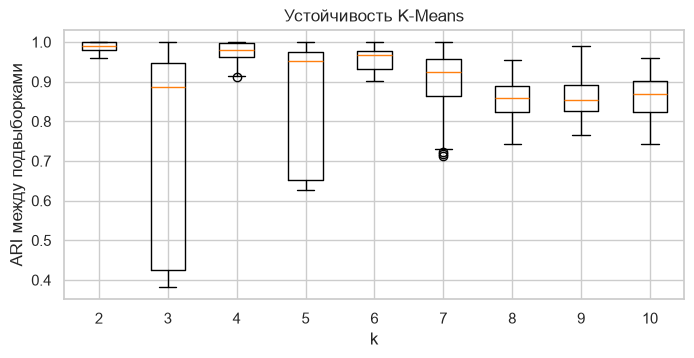

,2,3,4,5,6,7,8,9,10
mean ARI,0.988,0.724,0.973,0.848,0.957,0.891,0.859,0.863,0.862


In [12]:
rng = np.random.default_rng(SEED)
stab = {}
for k in K:
    s = []
    for _ in range(30):
        i, j = (rng.choice(len(X), int(0.8 * len(X)), replace=False) for _ in range(2))
        a = KMeans(k, n_init=10, random_state=int(rng.integers(1e6))).fit(X[i]).predict(X)
        b = KMeans(k, n_init=10, random_state=int(rng.integers(1e6))).fit(X[j]).predict(X)
        s.append(adjusted_rand_score(a, b))
    stab[k] = s

plt.figure(figsize=(8, 3.5))
plt.boxplot(list(stab.values()), tick_labels=list(stab.keys()))
plt.xlabel('k'); plt.ylabel('ARI между подвыборками'); plt.title('Устойчивость K-Means')
plt.show()
pd.Series({k: np.mean(v) for k, v in stab.items()}, name='mean ARI').round(3).to_frame().T

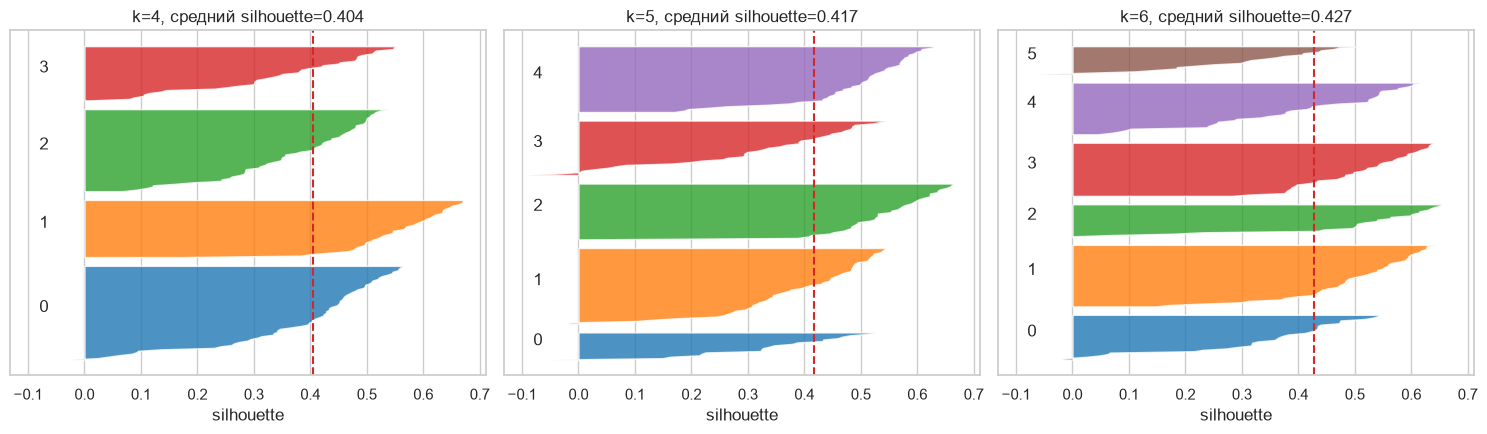

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for a, k in zip(ax, [4, 5, 6]):
    lab = KMeans(k, n_init=20, random_state=SEED).fit_predict(X)
    sil = silhouette_samples(X, lab)
    y = 0
    for c in range(k):
        v = np.sort(sil[lab == c])
        a.fill_betweenx(range(y, y + len(v)), 0, v, alpha=0.8)
        a.text(-0.08, y + len(v) / 2, str(c))
        y += len(v) + 5
    a.axvline(sil.mean(), c='C3', ls='--')
    a.set(title=f'k={k}, средний silhouette={sil.mean():.3f}', yticks=[], xlabel='silhouette')
plt.tight_layout(); plt.show()

In [14]:
K_BEST = 6

## сравнение методов кластеризации

EPS=0.55: кластеров 5, шум 27.5%


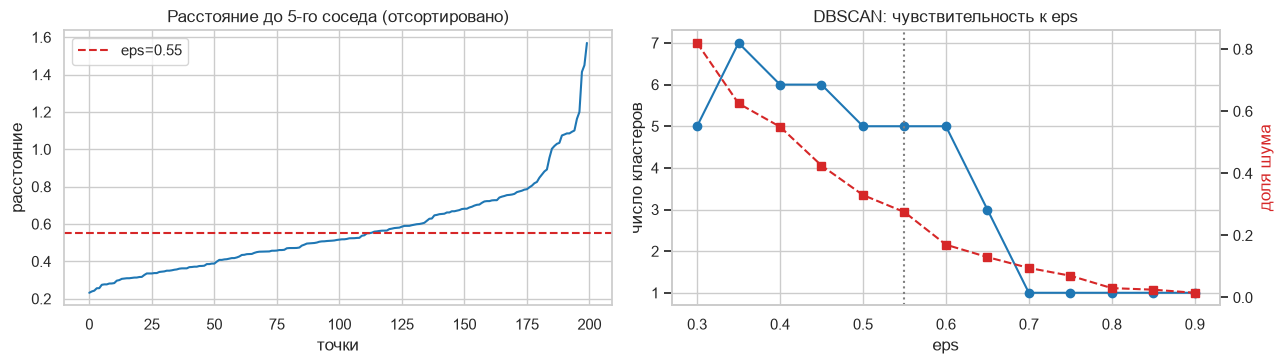

In [15]:
MIN_S = 6
dist = np.sort(NearestNeighbors(n_neighbors=MIN_S).fit(X).kneighbors(X)[0][:, -1])

eps_grid = np.arange(0.3, 0.91, 0.05)
res = [DBSCAN(eps=e, min_samples=MIN_S).fit_predict(X) for e in eps_grid]
n_cl = np.array([len(set(r) - {-1}) for r in res])
noise = np.array([(r == -1).mean() for r in res])
# лучший silhouette по всем точкам (шум = отдельная метка), как в сравнении методов ниже
sil = np.array([silhouette_score(X, r) if k > 1 else -np.inf for r, k in zip(res, n_cl)])
EPS = round(float(eps_grid[sil.argmax()]), 2)
print(f'EPS={EPS}: кластеров {n_cl[sil.argmax()]}, шум {100 * noise[sil.argmax()]:.1f}%')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(dist); ax[0].axhline(EPS, c='C3', ls='--', label=f'eps={EPS}')
ax[0].set(title=f'Расстояние до {MIN_S - 1}-го соседа (отсортировано)', xlabel='точки', ylabel='расстояние')
ax[0].legend()

ax[1].plot(eps_grid, n_cl, 'o-')
ax[1].axvline(EPS, c='grey', ls=':')
ax2 = ax[1].twinx()
ax2.plot(eps_grid, noise, 's--', c='C3')
ax[1].set(xlabel='eps', ylabel='число кластеров', title='DBSCAN: чувствительность к eps')
ax2.set_ylabel('доля шума', color='C3'); ax2.grid(False)
plt.tight_layout(); plt.show()

In [16]:
models = {
    'K-Means':        KMeans(K_BEST, n_init=50, random_state=SEED),
    'Agglo Ward':     AgglomerativeClustering(K_BEST, linkage='ward'),
    'Agglo average':  AgglomerativeClustering(K_BEST, linkage='average'),
    'Agglo complete': AgglomerativeClustering(K_BEST, linkage='complete'),
    'GMM':            GaussianMixture(K_BEST, n_init=10, random_state=SEED),
    'Spectral':       SpectralClustering(K_BEST, affinity='nearest_neighbors', n_neighbors=10, random_state=SEED),
    'DBSCAN':         DBSCAN(eps=EPS, min_samples=MIN_S),
    'HDBSCAN':        HDBSCAN(min_cluster_size=5),
}
labels = {n: m.fit_predict(X) for n, m in models.items()}

def scores(lab):
    # шум (-1) считается отдельной меткой, иначе методы с выбросом точек выглядят лучше
    m = lab != -1
    k = len(set(lab[m]))
    out = {'кластеров': k, 'шум, %': 100 * (~m).mean(), 'мин. размер': np.bincount(lab[m]).min()}
    if k > 1:
        out |= {'silhouette': silhouette_score(X, lab),
                'CH': calinski_harabasz_score(X, lab),
                'DB': davies_bouldin_score(X, lab),
                'silhouette без шума': silhouette_score(X[m], lab[m])}
    return out

cmp = pd.DataFrame({n: scores(l) for n, l in labels.items()}).T
cmp.style.format(precision=3).highlight_max(subset=['silhouette', 'CH'], color='#c6efce') \
   .highlight_min(subset=['DB'], color='#c6efce')

,кластеров,"шум, %",мин. размер,silhouette,CH,DB,silhouette без шума
K-Means,6.000,0.000,21.000,0.427,135.102,0.828,0.427
Agglo Ward,6.000,0.000,21.000,0.420,127.986,0.852,0.420
Agglo average,6.000,0.000,4.000,0.390,102.037,0.865,0.390
Agglo complete,6.000,0.000,16.000,0.375,109.415,1.000,0.375
GMM,6.000,0.000,13.000,0.377,107.591,0.871,0.377
Spectral,6.000,0.000,21.000,0.415,126.751,0.842,0.415
DBSCAN,5.000,27.500,10.000,0.238,43.304,1.908,0.484
HDBSCAN,6.000,37.500,9.000,0.173,31.285,1.699,0.557


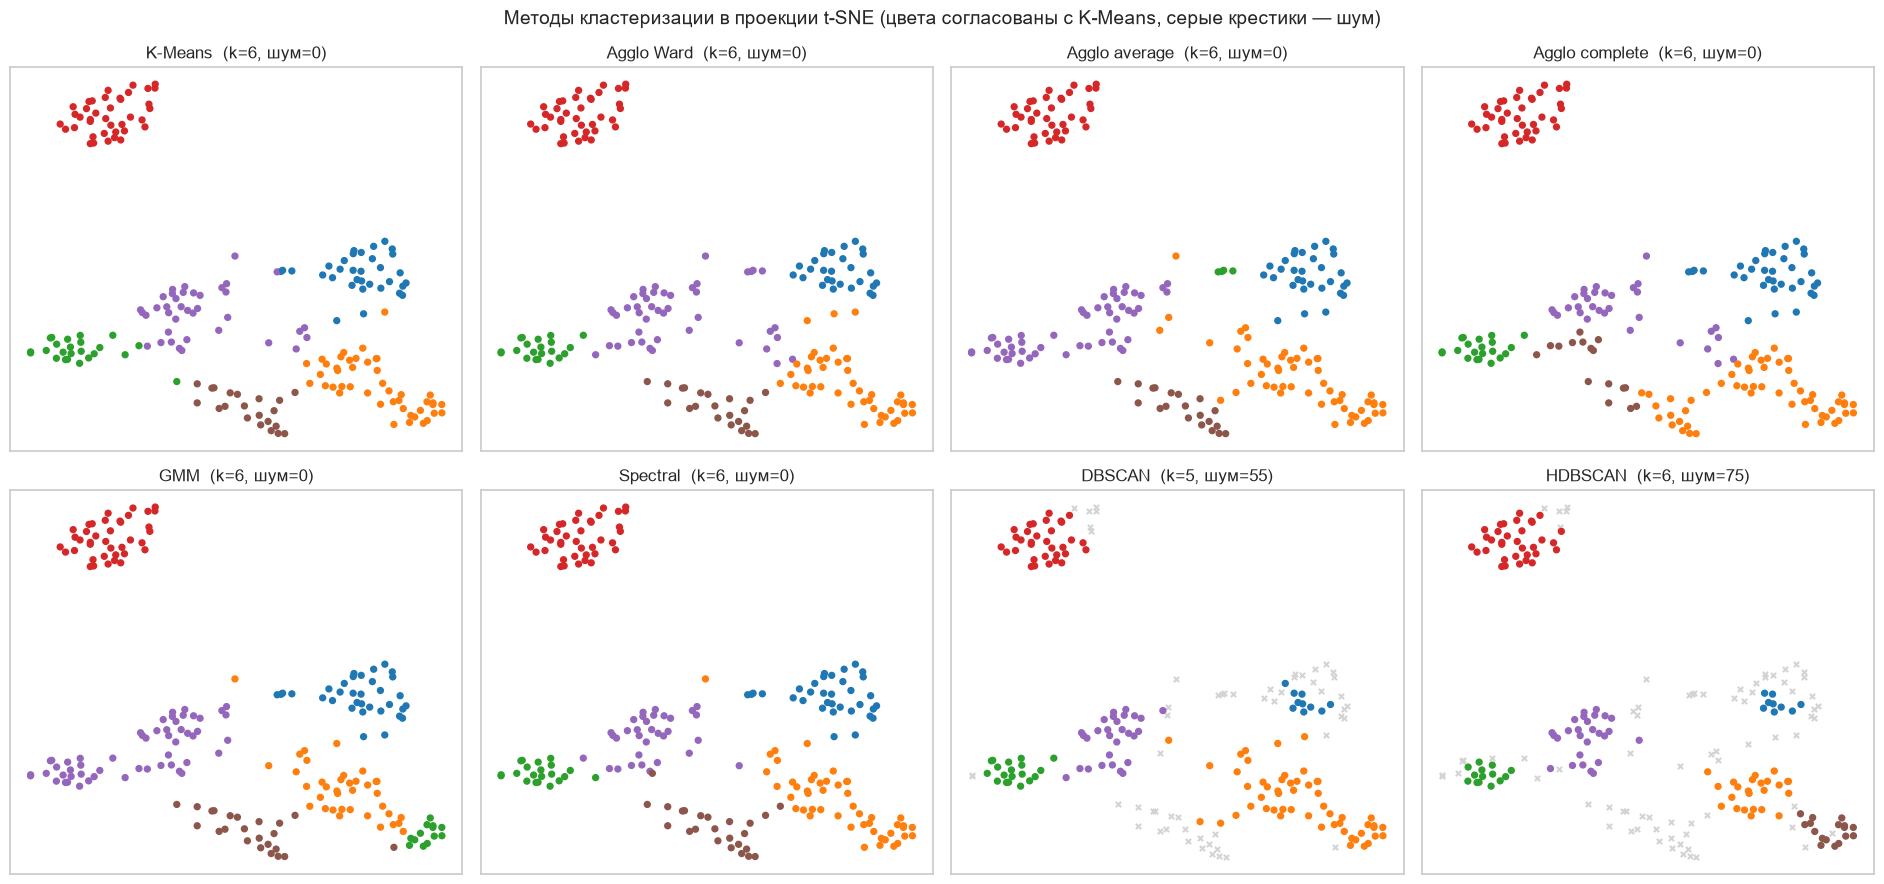

In [17]:
def align(lab, ref):
    # переименовать кластеры lab так, чтобы они совпадали с ref (венгерский алгоритм)
    cl = np.unique(lab[lab != -1])
    rc = np.unique(ref)
    cont = np.array([[np.sum((lab == a) & (ref == b)) for b in rc] for a in cl])
    r, c = linear_sum_assignment(-cont)
    new = dict(zip(cl[r], rc[c]))
    extra = iter(range(rc.max() + 1, rc.max() + 1 + len(cl)))
    new |= {a: next(extra) for a in cl if a not in new}
    return np.array([new.get(l, -1) for l in lab])

aligned = {n: align(lab, labels['K-Means']) for n, lab in labels.items()}
n_col = max(l.max() for l in aligned.values()) + 1
COLS = np.array(sns.color_palette('tab10') + sns.color_palette('husl', max(0, n_col - 10)))

fig, ax = plt.subplots(2, 4, figsize=(19, 9))
for a, (n, lab) in zip(ax.flat, aligned.items()):
    noise = lab == -1
    a.scatter(Z_tsne[noise, 0], Z_tsne[noise, 1], c='lightgrey', s=14, marker='x')
    a.scatter(Z_tsne[~noise, 0], Z_tsne[~noise, 1], c=COLS[lab[~noise]], s=18)
    a.set_title(f'{n}  (k={len(set(lab) - {-1})}, шум={noise.sum()})')
    a.set_xticks([]); a.set_yticks([])
plt.suptitle('Методы кластеризации в проекции t-SNE (цвета согласованы с K-Means, серые крестики — шум)', fontsize=14)
plt.tight_layout(); plt.show()

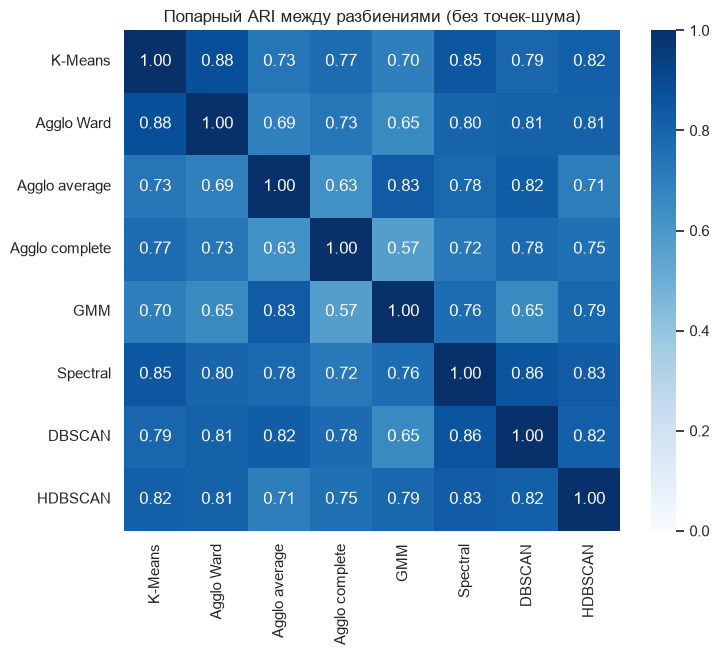

In [18]:
def ari_no_noise(a, b):
    m = (a != -1) & (b != -1)
    return adjusted_rand_score(a[m], b[m])

names = list(labels)
ari = pd.DataFrame([[ari_no_noise(labels[a], labels[b]) for b in names] for a in names],
                   index=names, columns=names)
plt.figure(figsize=(8, 6.5))
sns.heatmap(ari, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Попарный ARI между разбиениями (без точек-шума)'); plt.show()

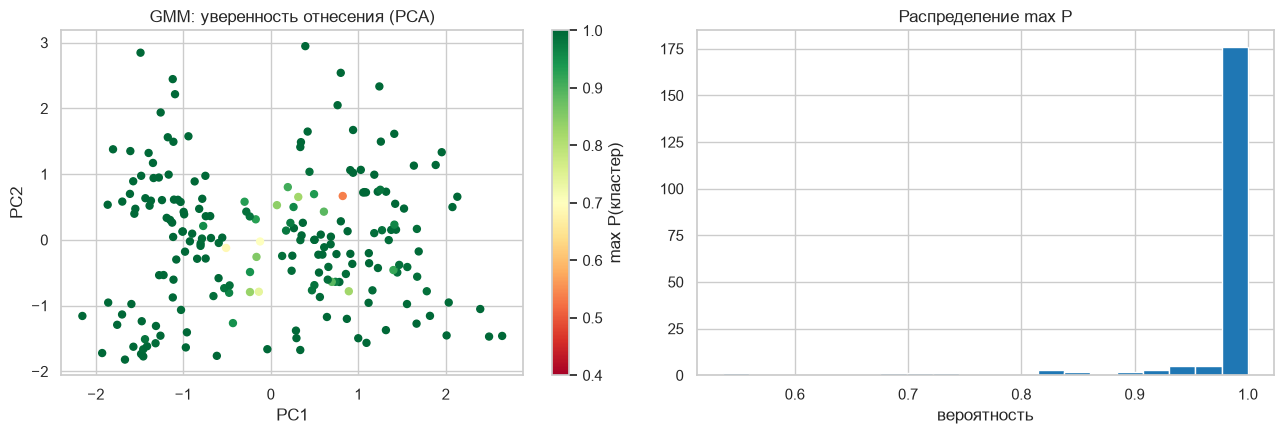

неуверенных точек (max P < 0.8): 4 из 200


In [19]:
gmm = models['GMM']
proba = gmm.predict_proba(X).max(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
s = ax[0].scatter(Z_pca[:, 0], Z_pca[:, 1], c=proba, cmap='RdYlGn', s=25, vmin=0.4, vmax=1)
plt.colorbar(s, ax=ax[0], label='max P(кластер)')
ax[0].set(title='GMM: уверенность отнесения (PCA)', xlabel='PC1', ylabel='PC2')
ax[1].hist(proba, bins=20); ax[1].set(title='Распределение max P', xlabel='вероятность')
plt.tight_layout(); plt.show()
print(f'неуверенных точек (max P < 0.8): {(proba < 0.8).sum()} из {len(X)}')

## кластеризация в пространстве сниженной размерности

In [20]:
base = labels['K-Means']
rows = []
for name, Z in {'исходные 3D': X, 'PCA-2': Z_pca, 'MDS-2': Z_mds, 't-SNE-2': Z_tsne, 'Isomap-2': Z_iso}.items():
    lab = KMeans(K_BEST, n_init=50, random_state=SEED).fit_predict(Z)
    rows.append({'пространство': name, 'ARI с K-Means 3D': adjusted_rand_score(base, lab),
                 'silhouette в исходном 3D': silhouette_score(X, lab)})
pd.DataFrame(rows).set_index('пространство').round(3)

,ARI с K-Means 3D,silhouette в исходном 3D
пространство,,
исходные 3D,1.000,0.427
PCA-2,0.689,0.319
MDS-2,0.586,0.356
t-SNE-2,0.916,0.420
Isomap-2,0.602,0.302


## интерпретация сегментов 

In [21]:
km = models['K-Means']
seg = df.copy()
seg['cluster'] = labels['K-Means']

prof = seg.groupby('cluster').agg(n=('Age', 'size'), Age=('Age', 'mean'), Income=('Income', 'mean'),
                                 Score=('Score', 'mean'), female_share=('Gender', lambda s: (s == 'Female').mean()))
prof = prof.sort_values(['Income', 'Score'])
prof.round(2)

,n,Age,Income,Score,female_share
cluster,,,,,
2,24,25.25,25.83,76.92,0.58
5,21,45.52,26.29,19.38,0.62
1,45,56.33,54.27,49.07,0.58
4,38,26.68,57.58,47.79,0.63
3,39,32.69,86.54,82.13,0.54
0,33,41.94,88.94,16.97,0.42


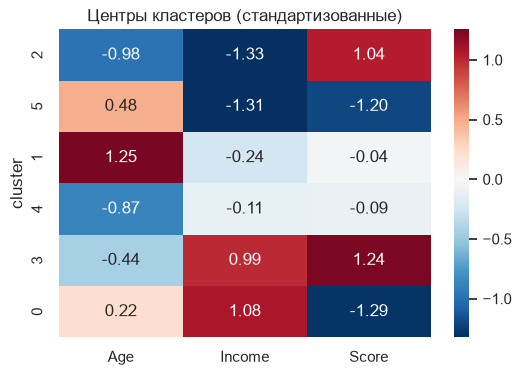

In [22]:
centers_z = pd.DataFrame(km.cluster_centers_, columns=FEATS).loc[prof.index]
plt.figure(figsize=(6, 4))
sns.heatmap(centers_z, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Центры кластеров (стандартизованные)'); plt.ylabel('cluster'); plt.show()

In [23]:
NAMES = {}
for c, r in prof.iterrows():
    inc = 'высокий доход' if r.Income > 70 else 'низкий доход' if r.Income < 40 else 'средний доход'
    sp = 'много тратят' if r.Score > 65 else 'мало тратят' if r.Score < 35 else 'тратят умеренно'
    age = 'молодые' if r.Age < 35 else 'старшие' if r.Age > 50 else 'средний возраст'
    NAMES[c] = f'{c}: {age}, {inc}, {sp}'
seg['segment'] = seg['cluster'].map(NAMES)
pd.Series(NAMES)

2            2: молодые, низкий доход, много тратят
5     5: средний возраст, низкий доход, мало тратят
1        1: старшие, средний доход, тратят умеренно
4        4: молодые, средний доход, тратят умеренно
3           3: молодые, высокий доход, много тратят
0    0: средний возраст, высокий доход, мало тратят
dtype: str

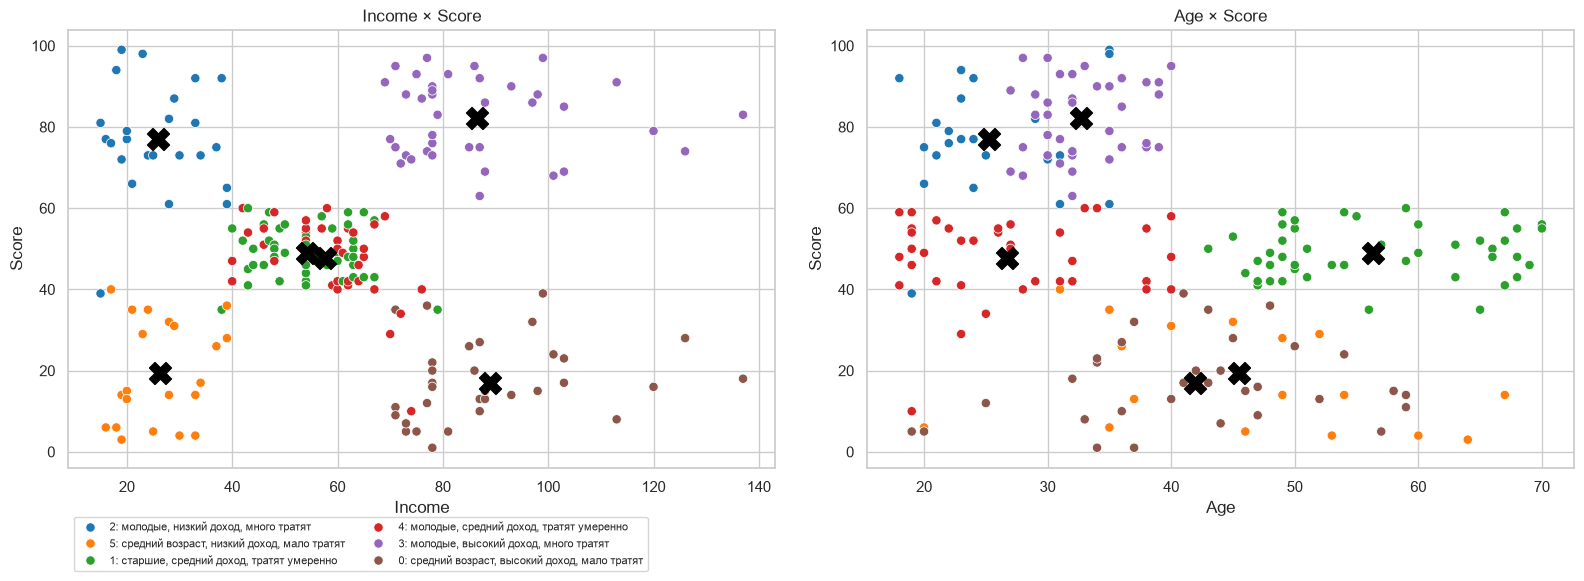

In [24]:
order = [NAMES[c] for c in prof.index]
pal = dict(zip(order, sns.color_palette('tab10', len(order))))
cz = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATS)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=seg, x='Income', y='Score', hue='segment', hue_order=order, palette=pal, s=45, ax=ax[0])
ax[0].scatter(cz.Income, cz.Score, marker='X', s=250, c='black')
ax[0].set_title('Income × Score'); ax[0].legend(fontsize=8, loc='upper left', bbox_to_anchor=(0, -0.1), ncol=2)
sns.scatterplot(data=seg, x='Age', y='Score', hue='segment', hue_order=order, palette=pal, s=45, ax=ax[1], legend=False)
ax[1].scatter(cz.Age, cz.Score, marker='X', s=250, c='black')
ax[1].set_title('Age × Score')
plt.tight_layout(); plt.show()

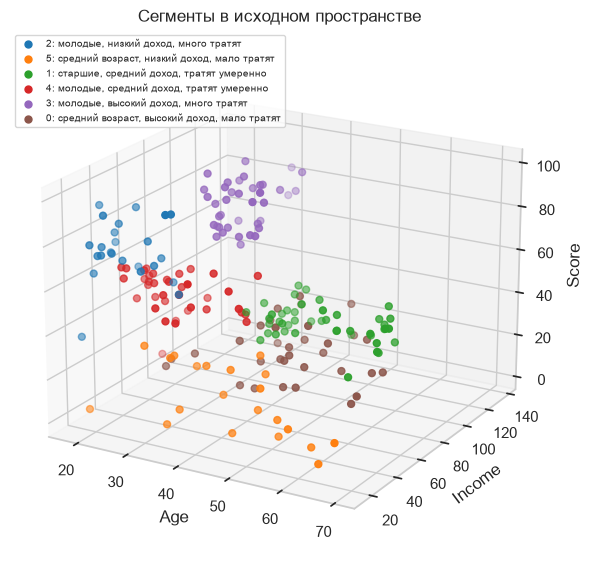

In [25]:
fig = plt.figure(figsize=(8, 7))
a = fig.add_subplot(projection='3d')
for s in order:
    d = seg[seg.segment == s]
    a.scatter(d.Age, d.Income, d.Score, s=25, color=pal[s], label=s)
a.set(xlabel='Age', ylabel='Income', zlabel='Score'); a.view_init(20, -60)
a.legend(fontsize=7, loc='upper left'); plt.title('Сегменты в исходном пространстве'); plt.show()

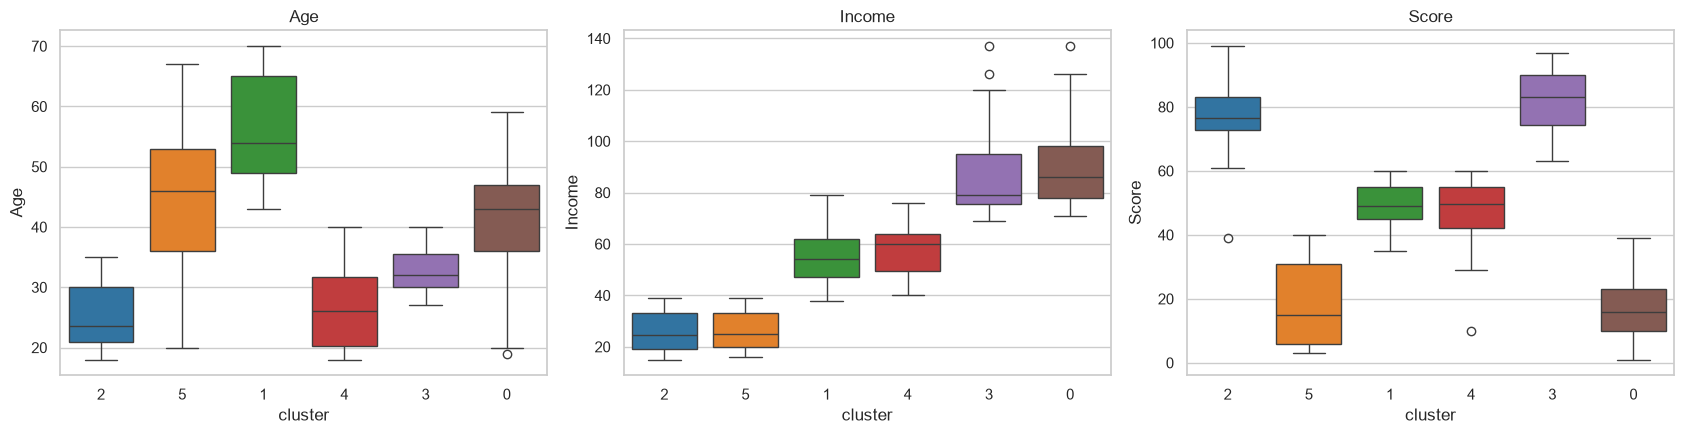

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, f in zip(ax, FEATS):
    sns.boxplot(data=seg, x='cluster', y=f, order=prof.index, hue='cluster', hue_order=prof.index,
                palette=[pal[NAMES[c]] for c in prof.index], legend=False, ax=a)
    a.set_title(f)
plt.tight_layout(); plt.show()

In [27]:
X2 = StandardScaler().fit_transform(seg[['Income', 'Score']])
lab2 = KMeans(5, n_init=50, random_state=SEED).fit_predict(X2)
print('silhouette 2D-решения k=5 в исходном 3D:', round(silhouette_score(X, lab2), 3),
      '| у 3D-решения k=6:', round(silhouette_score(X, seg.cluster), 3))
print('ARI с 3D-решением k=6:', round(adjusted_rand_score(seg.cluster, lab2), 3))
pd.crosstab(seg.segment, lab2, colnames=['кластер 2D'])

silhouette 2D-решения k=5 в исходном 3D: 0.342 | у 3D-решения k=6: 0.427
ARI с 3D-решением k=6: 0.691


кластер 2D,0,1,2,3,4
segment,,,,,
"0: средний возраст, высокий доход, мало тратят",1,0,0,32,0
"1: старшие, средний доход, тратят умеренно",43,0,0,1,1
"2: молодые, низкий доход, много тратят",1,0,22,0,1
"3: молодые, высокий доход, много тратят",0,39,0,0,0
"4: молодые, средний доход, тратят умеренно",36,0,0,2,0
"5: средний возраст, низкий доход, мало тратят",0,0,0,0,21
